# v3 — risk-aware sizing (inverse basis-vol)

v2.1 fixed *selection* (veto the dislocated-basis tail) but still **equal-weights** the ~115 held
names. Equal weight is risk-blind: a name with 10× the basis-return vol contributes ~10× the risk for
the same weight. v3 keeps v2.1's selection unchanged and only changes the **weighting** to
**∝ 1/basis_vol** — risk parity on the delta-neutral leg, which up-weights the clean-basis majors and
down-weights the volatile names. Everything is booked through `lab.py` (reproduces the production
`engine.run` to 1e-6, sizing path included).

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'
import sys; from pathlib import Path
_p = Path.cwd().resolve()
ROOT = next((q for q in [_p, *_p.parents] if (q/'pyproject.toml').exists()), _p)
sys.path[:0] = [str(ROOT)]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import research.funding_carry.lab as H
from src.common import config as cfg
plt.rcParams.update({'figure.figsize':(14,3.8),'axes.grid':True,'grid.alpha':0.25,
                     'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
NAVY,TEAL,AMBER,RED,GREY='#1f3a5f','#2a9d8f','#e0a32e','#c1121f','0.6'
COSTS = cfg.load_config('strategies/funding_carry/v3.yaml')['costs']
maj, non = H.universe(); MAJ = set(maj); P = H.load_panels(maj + non)
SPECS = [{'name':'funding_vol','window':30},{'name':'neg_freq','window':30},{'name':'basis','window':30}]
VETO  = [{'feature':'funding_vol','direction':'max','cap':0.75},
         {'feature':'neg_freq','direction':'max','cap':0.40},
         {'feature':'basis','direction':'max','cap':0.01}]
V21 = H.evaluate_select(P,7,0.08,0.02,None,None,COSTS,feature_specs=SPECS,veto_rules=VETO,warmup_days=30)          # equal
V3  = H.evaluate_select(P,7,0.08,0.02,None,None,COSTS,feature_specs=SPECS,veto_rules=VETO,size_kind='inv_basis_vol',warmup_days=30)  # inv-vol
def kpi(res):
    a,b=res['1.0x'],res['2.0x']; W=res['W']; dep=W[(W>0).any(axis=1)]
    return {'net%':round(a['ann_return']*100,1),'Sharpe':a['sharpe'],'net@2x%':round(b['ann_return']*100,1),
            'Sh@2x':b['sharpe'],'maxDD%':round(a['max_drawdown']*100,1),'turn':round(a['ann_turnover'],0),
            'names':round(a['avg_names_held'],0),'maxW%':round(dep.max(axis=1).mean()*100,1),
            'effN':round((1/(dep**2).sum(axis=1)).mean(),0)}
def eq(res): return res['net'].cumsum()*100
print(pd.DataFrame({'v2.1 equal-weight':kpi(V21),'v3 inv-basis-vol':kpi(V3)}).T.to_string())

                   net%  Sharpe  net@2x%  Sh@2x  maxDD%  turn  names  maxW%   effN
v2.1 equal-weight  10.4   5.404      6.6  3.365    -2.6  20.0  114.0    2.1  113.0
v3 inv-basis-vol    9.0   5.747      4.1  2.458    -3.3  26.0  114.0    5.7   88.0


## 1. Equal weight is risk-blind

On a snapshot day, plot each held name's **weight vs its basis-vol**. Equal weight is a flat line
(every name 1/N regardless of risk); inverse-vol slopes down (more weight to low-risk names). The
majors (red) sit at the low-vol end — inverse-vol lifts them, equal weight buries them at ~1/115.

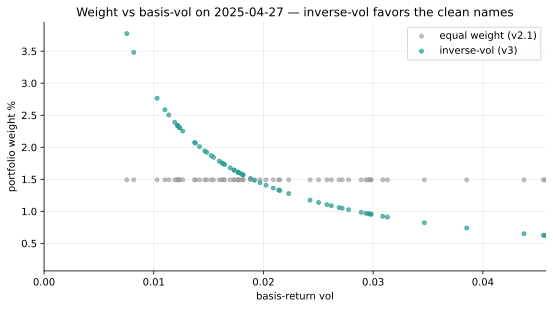

In [2]:
W3 = V3['W']; W1 = V21['W']
bvol = H.feature_panels(P, [{'name':'basis_vol','window':30}])['basis_vol']
day = W3[(W3>0).sum(axis=1) >= 50].index[-400]         # a well-populated recent day
held = W3.columns[W3.loc[day] > 0]
x = bvol.loc[day, held].values; ye = W1.loc[day, held].values*100; yi = W3.loc[day, held].values*100
fig, ax = plt.subplots(figsize=(9,4.5))
ax.scatter(x, ye, s=16, color=GREY, alpha=0.6, label='equal weight (v2.1)')
ax.scatter(x, yi, s=16, color=TEAL, alpha=0.7, label='inverse-vol (v3)')
for s in [m for m in maj if m in held]:
    ax.scatter(bvol.loc[day,s], W3.loc[day,s]*100, s=90, color=RED, zorder=5)
    ax.annotate(s.replace('usdt','').upper(),(bvol.loc[day,s],W3.loc[day,s]*100),fontsize=8,xytext=(4,3),textcoords='offset points')
ax.set_xlabel('basis-return vol'); ax.set_ylabel('portfolio weight %'); ax.legend()
ax.set_xlim(0, np.nanpercentile(x, 90)); ax.set_title(f'Weight vs basis-vol on {day.date()} — inverse-vol favors the clean names')
plt.show()

## 2. Does it pay? v2.1 (equal) vs v3 (inverse-vol)

Same selection, only the weighting differs. Inverse-vol raises net Sharpe and shrinks drawdown while
keeping breadth (effective N stays ~90, max weight ~6% — no cap needed).

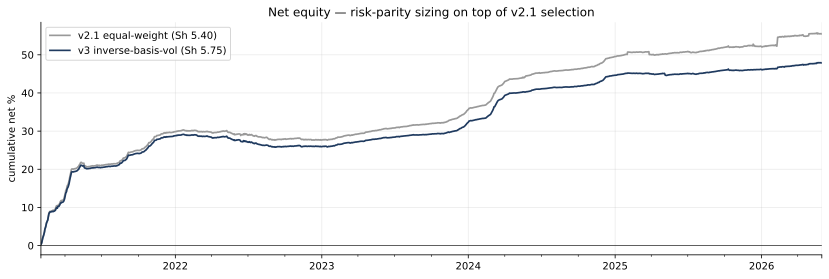

In [3]:
fig, ax = plt.subplots(figsize=(14,4.2))
for lab_,res,c in [(f"v2.1 equal-weight (Sh {V21['1.0x']['sharpe']:.2f})",V21,GREY),
                   (f"v3 inverse-basis-vol (Sh {V3['1.0x']['sharpe']:.2f})",V3,NAVY)]:
    eq(res).plot(ax=ax, color=c, lw=1.7, label=lab_)
ax.axhline(0,color='k',lw=0.6); ax.set_ylabel('cumulative net %'); ax.legend()
ax.set_title('Net equity — risk-parity sizing on top of v2.1 selection')
plt.show()

## 3. The book stays diversified

Inverse-vol does **not** collapse into a few names: effective N (1/Σwᵢ²) stays ~90 and the top
weight stays modest. Below: effective number of names held over time, and the weight paths of the
majors (lifted) vs a typical mid-vol name.

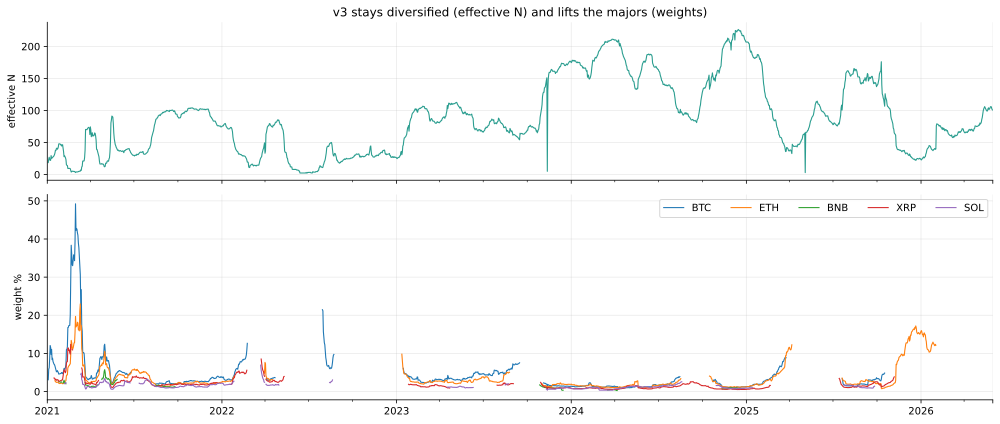

avg effective N 88 | avg max weight 5.7%


In [4]:
dep = W3[(W3>0).any(axis=1)]
effN = 1.0/(dep**2).sum(axis=1)
fig,(a1,a2)=plt.subplots(2,1,figsize=(14,6),sharex=True,gridspec_kw={'height_ratios':[1,1.3]})
effN.plot(ax=a1,color=TEAL,lw=1.1); a1.set_ylabel('effective N'); a1.set_title('v3 stays diversified (effective N) and lifts the majors (weights)')
for s in [m for m in maj if m in W3.columns]:
    (W3[s]*100).replace(0,np.nan).plot(ax=a2,lw=1.1,label=s.replace('usdt','').upper())
a2.set_ylabel('weight %'); a2.legend(ncol=5); plt.tight_layout(); plt.show()
print(f"avg effective N {effN.mean():.0f} | avg max weight {dep.max(axis=1).mean():.1%}")

## 4. Validation — robust OOS, at a turnover cost

By-year Sharpe and a temporal train/test split. Inverse-vol is the **most out-of-sample-robust**
variant (test-period Sharpe actually rises). The honest cost: it **churns more** (weights drift with
vol daily), so its **2× cost Sharpe is lower** than equal-weight v2.1 — still well above the 0.5 bar.
Cutting that turnover with a no-trade weight band is v3.1.

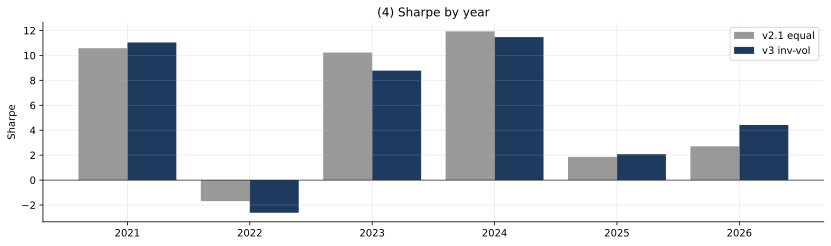

Temporal split (train 2021-2023 -> TEST 2024-2026):
            train Sh  TEST Sh  TEST net%  TEST DD%  TEST Sh@2x
v2.1 equal     5.883    4.778        8.3      -0.9       3.392
v3 inv-vol     5.766    6.722        6.5      -0.6       2.646


In [5]:
def by_year(res): return {int(y):v['sharpe'] for y,v in res['1.0x']['by_year'].items()}
yv = pd.DataFrame({'v2.1 equal':by_year(V21),'v3 inv-vol':by_year(V3)})
x=np.arange(len(yv)); w=0.4
fig,ax=plt.subplots(figsize=(14,3.6))
ax.bar(x-w/2,yv['v2.1 equal'].values,w,color=GREY,label='v2.1 equal')
ax.bar(x+w/2,yv['v3 inv-vol'].values,w,color=NAVY,label='v3 inv-vol')
ax.axhline(0,color='k',lw=0.6); ax.set_xticks(x); ax.set_xticklabels(yv.index); ax.set_ylabel('Sharpe'); ax.legend()
ax.set_title('(4) Sharpe by year'); plt.show()

DID=P['didx']; tr=H._window_mask(DID,end='2023-12-31'); te=H._window_mask(DID,start='2024-01-01')
def split(**kw):
    a=H.evaluate_select(P,7,0.08,0.02,None,None,COSTS,feature_specs=SPECS,veto_rules=VETO,mask=tr,warmup_days=30,**kw)
    b=H.evaluate_select(P,7,0.08,0.02,None,None,COSTS,feature_specs=SPECS,veto_rules=VETO,mask=te,warmup_days=30,**kw)
    return {'train Sh':a['1.0x']['sharpe'],'TEST Sh':b['1.0x']['sharpe'],'TEST net%':round(b['1.0x']['ann_return']*100,1),
            'TEST DD%':round(b['1.0x']['max_drawdown']*100,1),'TEST Sh@2x':b['2.0x']['sharpe']}
oos=pd.DataFrame({'v2.1 equal':split(),'v3 inv-vol':split(size_kind='inv_basis_vol')}).T
print('Temporal split (train 2021-2023 -> TEST 2024-2026):'); print(oos.to_string())

## 5. v3.1 — a no-trade band on the reweights

v3's extra turnover isn't selection — it's **reweighting**. Decomposing turnover into entries/exits
vs weight changes within the held set shows the reweight component jumps from ~9× (v2.1) to ~16×
(v3.0). Much of that is chasing **noise** in the 30-day vol estimate. A per-name **deadband** — only
reweight a name when its inverse-vol target drifts more than `band` (relative) — damps it.

In [6]:
def decomp(res):
    W=res['W']; Wp=W.shift(1).fillna(0.0); d=(W-Wp).abs(); cont=(W>0)&(Wp>0); yrs=len(W)/365
    return dict(total=d.sum(axis=1).sum()/yrs, selection=d.where(~cont,0).sum(axis=1).sum()/yrs,
                reweight=d.where(cont,0).sum(axis=1).sum()/yrs)
print('turnover/yr decomposition:')
for tag,res in [('v2.1 equal',V21),('v3.0 inv-vol',V3)]:
    c=decomp(res); print(f"  {tag:14} total {c['total']:.1f}x = selection {c['selection']:.1f}x + reweight {c['reweight']:.1f}x")

def evb(band=None,mask=None):
    return H.evaluate_select(P,7,0.08,0.02,None,None,COSTS,feature_specs=SPECS,veto_rules=VETO,
                             size_kind='inv_basis_vol',band=band,mask=mask,warmup_days=30)
BANDS=[0.10,0.20,0.35,0.50,0.75,1.00,1.50]
sw=pd.DataFrame({f'{b:.2f}':{'Sh@1x':evb(b)['1.0x']['sharpe'],'Sh@2x':evb(b)['2.0x']['sharpe'],
                             'turn':evb(b)['1.0x']['ann_turnover']} for b in BANDS}).T
print('\nband sweep:'); print(sw.round(2).to_string())

turnover/yr decomposition:
  v2.1 equal     total 20.6x = selection 11.4x + reweight 9.2x
  v3.0 inv-vol   total 26.6x = selection 10.7x + reweight 15.9x



band sweep:
      Sh@1x  Sh@2x  turn
0.10   6.08   3.09  23.1
0.20   6.16   3.29  22.1
0.35   6.27   3.50  21.1
0.50   6.32   3.62  20.5
0.75   6.42   3.80  19.7
1.00   6.46   3.88  19.4
1.50   6.52   4.04  18.7


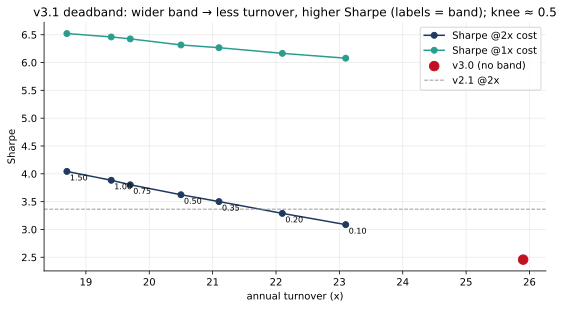

In [7]:
# Trade-off curve: turnover vs 2x-cost Sharpe as the band widens
res_b=[evb(b) for b in BANDS]
turn=[r['1.0x']['ann_turnover'] for r in res_b]; sh1=[r['1.0x']['sharpe'] for r in res_b]; sh2=[r['2.0x']['sharpe'] for r in res_b]
fig,ax=plt.subplots(figsize=(9,4.5))
ax.plot(turn,sh2,'-o',color=NAVY,label='Sharpe @2x cost'); ax.plot(turn,sh1,'-o',color=TEAL,label='Sharpe @1x cost')
for b,t,s in zip(BANDS,turn,sh2): ax.annotate(f'{b:.2f}',(t,s),fontsize=8,xytext=(3,-9),textcoords='offset points')
v30=evb(None); ax.scatter([v30['1.0x']['ann_turnover']],[v30['2.0x']['sharpe']],s=90,color=RED,zorder=5,label='v3.0 (no band)')
ax.axhline(V21['2.0x']['sharpe'],color=GREY,ls='--',lw=1,label='v2.1 @2x')
ax.set_xlabel('annual turnover (x)'); ax.set_ylabel('Sharpe'); ax.legend()
ax.set_title('v3.1 deadband: wider band → less turnover, higher Sharpe (labels = band); knee ≈ 0.5')
plt.show()

**band = 0.5 (the knee):** cuts turnover back to ~v2.1 levels while lifting **both** 1× and 2×
Sharpe above v3.0 — the band removes noise-chasing reweights, not signal. Wider bands help marginally
more but approach *freeze-at-entry* (over-fit-prone), so 0.5 is the conservative pick.

                net%  Sharpe  net@2x%  Sh@2x  maxDD%  turn  names  maxW%   effN
v2.1 equal      10.4   5.404      6.6  3.365    -2.6  20.0  114.0    2.1  113.0
v3.0 inv-vol     9.0   5.747      4.1  2.458    -3.3  26.0  114.0    5.7   88.0
v3.1 +band 0.5   9.9   6.316      6.0  3.624    -2.8  20.0  114.0    5.6   89.0


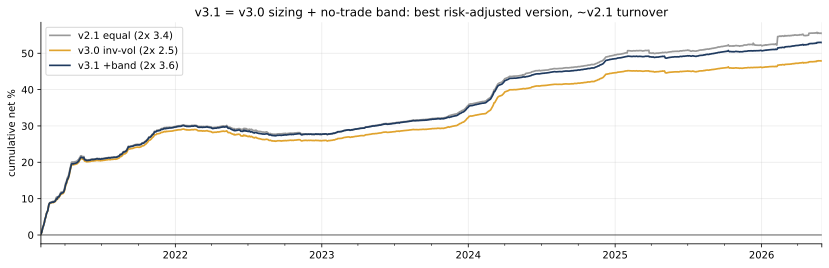


band OOS (train 21-23 -> TEST 24-26):
           train Sh  TEST Sh@1x  TEST Sh@2x  TEST turn
band None      5.77        6.72        2.65       19.3
band 0.5       6.25        7.52        4.32       14.2


In [8]:
V31 = evb(0.50)
print(pd.DataFrame({'v2.1 equal':kpi(V21),'v3.0 inv-vol':kpi(V3),'v3.1 +band 0.5':kpi(V31)}).T.to_string())
fig,ax=plt.subplots(figsize=(14,4))
for lab_,res,c in [(f"v2.1 equal (2x {V21['2.0x']['sharpe']:.1f})",V21,GREY),
                   (f"v3.0 inv-vol (2x {V3['2.0x']['sharpe']:.1f})",V3,AMBER),
                   (f"v3.1 +band (2x {V31['2.0x']['sharpe']:.1f})",V31,NAVY)]:
    eq(res).plot(ax=ax,color=c,lw=1.7,label=lab_)
ax.axhline(0,color='k',lw=0.6); ax.set_ylabel('cumulative net %'); ax.legend()
ax.set_title('v3.1 = v3.0 sizing + no-trade band: best risk-adjusted version, ~v2.1 turnover'); plt.show()
# OOS for the band
oosb=pd.DataFrame({f'band {b}':{'train Sh':evb(b,tr)['1.0x']['sharpe'],'TEST Sh@1x':evb(b,te)['1.0x']['sharpe'],
        'TEST Sh@2x':evb(b,te)['2.0x']['sharpe'],'TEST turn':evb(b,te)['1.0x']['ann_turnover']}
        for b in [None,0.5]}).T
print('\nband OOS (train 21-23 -> TEST 24-26):'); print(oosb.round(2).to_string())

## Takeaways

- **Risk-parity sizing (∝ 1/basis_vol) is the right weighting** — on v2.1's selection it lifts net
  Sharpe ~5.4 → ~5.75 and shrinks drawdown by putting weight where basis risk is low (the majors),
  staying diversified (effective N ~90, max weight ~6%, **no cap needed**).
- **v3.1 = + a no-trade band (0.5)** is the best version yet: net Sharpe **6.32**, **2×-cost Sharpe
  3.62** (both above v2.1 and v3.0), DD ~−3%, turnover back to ~20× (≈ v2.1). The band cuts the
  noisy vol-driven reweighting, so it *lowers cost AND denoises the tilt* — helping 1× and 2× alike.
  Robust OOS (test-period Sharpe rises). Wider bands help marginally more but approach freeze-at-entry.
- Caveats: gross-of-slippage-capacity; a held name whose basis-vol isn't yet estimable (first day of
  a new listing) isn't held (can't size it); knobs/veto/band inherited settings — validate held-out
  before trusting magnitudes. Next levers are execution/capacity (maker fills, sizing to ADV), not
  more in-sample knob-tuning.